# Pronóstico del precio de bolsa de energía en Colombia

Paso 3. Los dos pasos anteriores bajan los datos (`1_descargar.py`) y arman el
panel diario (`2_construir_panel.py`). Este notebook deja listos los datos para
modelar: carga el panel, lo limpia, transforma el precio y construye todas las
características con `features.py`. El modelo está en `4_modelo_xgboost.ipynb`.

### Qué se predice

$$y_t^{(h)} = \log P_{t+h} - \log P_t$$

el cambio del logaritmo del precio en $h$ días. El precio se reconstruye como
$\hat P_{t+h} = P_t \, e^{\hat y}$.

Se trabaja con el cambio y no con el nivel porque, con el nivel, un modelo que
solo copia el precio de ayer ya parece muy bueno. Con el cambio, copiar el precio
de hoy es el punto de partida (el modelo "ingenuo", que predice $\hat y = 0$) y
cualquier mejora sobre eso es información de verdad.

### Las ventanas de tiempo

Quedan definidas en la sección 1 por si se quieren usar:

| Ventana | Fechas | Para qué se usaron en la versión anterior |
|---|---|---|
| Selección | 2015-2019 | ordenar las variables por importancia |
| Validación | 2020-2022 | elegir cuántas variables y calibrar los intervalos |
| Prueba A | 2023-2025 | primera medición |
| Prueba B | 2026 | medición final |

---
## 1. Preparación

En el computador los paneles están en `paneles/` y no hay que hacer nada. En
Colab hacen falta dos archivos además de este notebook: `features.py` y
`panel_diario.csv`. Se suben al panel de archivos antes de correr la celda; si no
están, la celda abre el botón para subirlos. Para modelar por hora hace falta
además `panel_horario_completo.csv.gz` (sección 4b); si no está, esa sección se
salta.

Los dos tienen que ser de la misma versión: `features.py` decide qué variables
son eventos (se llenan con cero) y cuáles se publican antes del despacho, y esas
listas cambian cuando el panel trae variables nuevas.

In [1]:
import importlib.util, subprocess, sys
from pathlib import Path

if importlib.util.find_spec("statsmodels") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "statsmodels"], check=True)

for archivo in ["features.py", "panel_diario.csv"]:
    if not Path(archivo).exists() and not (Path("paneles") / archivo).exists():
        from google.colab import files
        print(f"Sube {archivo}")
        files.upload()
# opcional: solo si se va a modelar por hora (sección 4b)
if not any(Path(d, "panel_horario_completo.csv.gz").exists() for d in (".", "paneles")):
    print("No está panel_horario_completo.csv.gz: la sección 4b se salta")
print("Archivos listos")

Archivos listos


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

import features as fe

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (13, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

FIN_SELECCION  = pd.Timestamp("2019-12-31")
INI_VALIDACION = pd.Timestamp("2020-01-01")
FIN_VALIDACION = pd.Timestamp("2022-12-31")
INI_PRUEBA     = pd.Timestamp("2023-01-01")
INI_2026       = pd.Timestamp("2026-01-01")

panel = fe.leer_panel()
print(f"{panel.shape[0]} días x {panel.shape[1]} variables, "
      f"del {panel.index.min().date()} al {panel.index.max().date()}")

4300 días x 171 variables, del 2015-01-01 al 2026-10-09


---
## 2. La serie que se quiere pronosticar

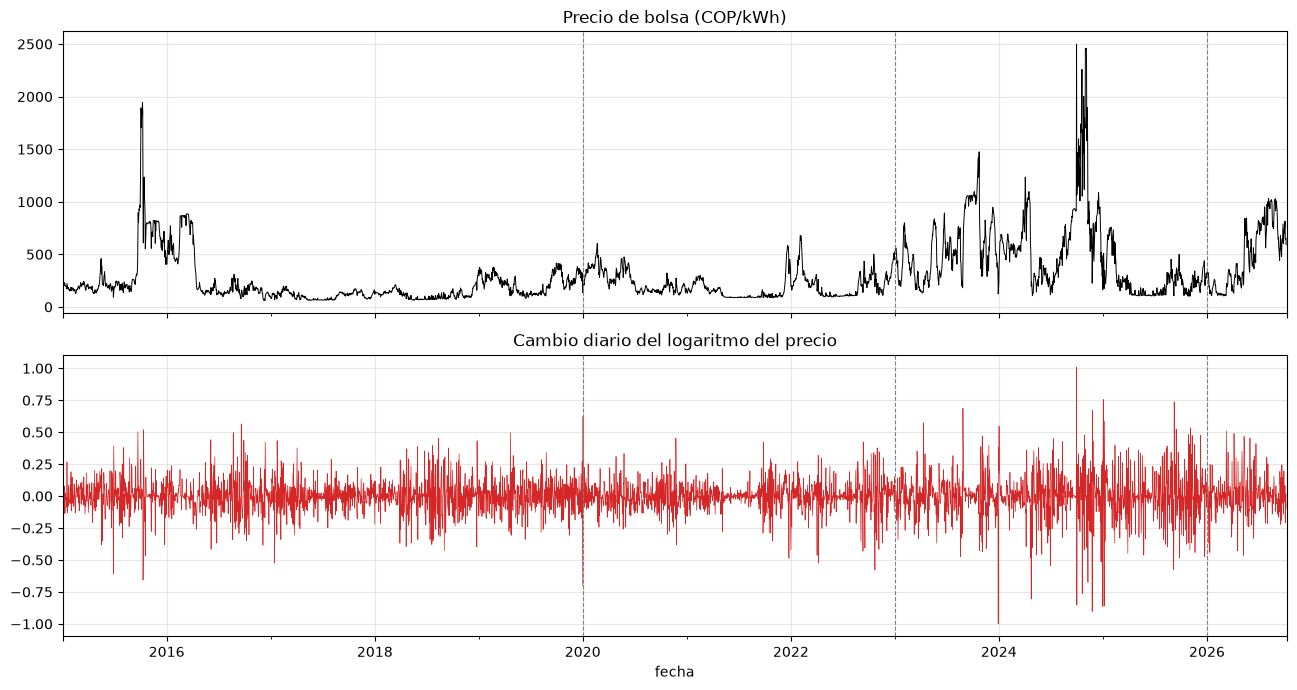

precio          prueba ADF: p = 0.0004
log precio      prueba ADF: p = 0.0072
cambio del log  prueba ADF: p = 0.0000


In [3]:
precio = panel[fe.OBJETIVO]
log_precio = np.log(precio)
dlog = log_precio.diff()

fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
precio.plot(ax=ax[0], color="k", lw=0.7, title="Precio de bolsa (COP/kWh)")
dlog.plot(ax=ax[1], color="tab:red", lw=0.5, title="Cambio diario del logaritmo del precio")
for a in ax:
    for f in [INI_VALIDACION, INI_PRUEBA, INI_2026]:
        a.axvline(f, color="gray", ls="--", lw=0.8)
plt.tight_layout(); plt.show()

for nombre, s in [("precio", precio), ("log precio", log_precio), ("cambio del log", dlog)]:
    p = adfuller(s.dropna(), autolag="AIC")[1]
    print(f"{nombre:15s} prueba ADF: p = {p:.4f}")

La prueba ADF rechaza raíz unitaria incluso en el nivel, así que formalmente no
obligaría a diferenciar. Se diferencia de todas formas por dos razones que la
prueba no mira: el nivel tiene picos de más de 2.500 COP/kWh con una varianza que
cambia mucho entre años, y, sobre todo, la razón de la sección anterior: modelar
el cambio obliga al modelo a decir algo más que "igual que ayer".

El año de prueba merece una mirada aparte:

In [4]:
p26 = precio[precio.index >= INI_2026].dropna()
mensual = p26.resample("MS").mean()
print(f"2026: de {p26.min():.0f} a {p26.max():.0f} COP/kWh; el mes más caro "
      f"fue {mensual.max() / mensual.min():.1f} veces el más barato\n")

tabla = pd.DataFrame({
    "precio": mensual,
    "Niño 1+2 semanal": panel["nino12_anom"].resample("MS").mean(),
    "ONI": panel["oni"].resample("MS").mean(),
}).loc["2025-11":].round(2)
tabla

2026: de 105 a 1031 COP/kWh; el mes más caro fue 7.6 veces el más barato



,precio,Niño 1+2 semanal,ONI
fecha,,,
2025-11-01,NaN,-0.25,-0.43
2025-12-01,NaN,-0.32,-0.57
2026-01-01,212.39,-0.47,-0.61
2026-02-01,124.42,0.57,-0.60
2026-03-01,220.20,1.19,-0.39
2026-04-01,269.01,1.50,-0.21
2026-05-01,504.99,1.71,0.11
2026-06-01,546.31,2.57,0.46
2026-07-01,789.80,3.37,0.95


En febrero de 2026 la temperatura frente a Ecuador (Niño 1+2) ya estaba casi un
grado por encima de lo normal, mientras el ONI, que es un promedio de tres meses
publicado con rezago, todavía marcaba La Niña. El precio empezó a subir en mayo.
Esa diferencia de meses es la razón por la que el panel trae la serie semanal y no
solo el ONI.

---
## 3. Limpieza: qué variables entran

Todo lo de esta sección y la siguiente está en `features.py`. Aquí se llama y se
explica.

Hay tres tipos de dato faltante y cada uno se trata distinto:

1. Eventos. Vertimientos, importaciones, exportaciones, generación solar y eólica,
   y desde la última versión también el vertido por embalse, la demanda no
   atendida y los intercambios con Ecuador.
   XM no publica fila cuando el evento no ocurre, y en once años ninguna de estas
   series tiene un cero. El hueco es un cero real y se llena con 0. Es la
   imputación con un valor fijo del curso de Soledad Galli (sección 5, cuaderno
   *Arbitrary Value Imputation*), solo que aquí el valor no es arbitrario: es el
   que corresponde.
2. Variables que arrancan tarde. Rellenar años antes de que existieran sería
   inventar datos. Además, una sola variable que empieza tarde le recorta el
   inicio a toda la muestra, porque el modelo necesita todas las columnas el mismo
   día. Se descartan.
3. Huecos de uno o dos días (festivos, fallas de publicación). Se llenan con el
   último valor conocido, que solo mira al pasado.

In [5]:
# comprobación del supuesto de los eventos: si no hay ceros, el hueco es "no ocurrió"
for c in ["vertimientos", "importaciones", "exportaciones"]:
    s = panel[c]
    print(f"{c:14s} faltante {s.isna().mean():5.1%}   ceros exactos: {(s == 0).sum()}")

base, descartes = fe.preparar_panel(panel)
print()
for motivo, columnas in descartes.items():
    print(f"Fuera por {motivo}: {columnas}")
print(f"\nEntran {base.shape[1]} variables (incluye 1/volumen útil, que se agrega aquí)")

vertimientos   faltante 37.4%   ceros exactos: 0
importaciones  faltante 13.8%   ceros exactos: 0
exportaciones  faltante  9.6%   ceros exactos: 0

Fuera por despacho: ['costo_marginal_prog', 'precio_oferta_desp']
Fuera por arrancan tarde: ['vol_pct_el_quimbo', 'pred_lluvia_pacifica']
Fuera por muchos faltantes: ['precio_esca_act', 'precio_esca_inf', 'precio_esca_marg', 'precio_esca_sup', 'alerta_niveles_bajos', 'alerta_crecientes', 'alerta_incendios', 'alerta_deslizamientos', 'lluvia_max_municipio']

Entran 158 variables (incluye 1/volumen útil, que se agrega aquí)


Las dos variables de despacho se dejan fuera a propósito. El precio de bolsa es
el costo marginal del despacho, así que estas variables son casi el mismo precio:

In [6]:
c = panel[["costo_marginal_prog", fe.OBJETIVO]].dropna()
print(f"correlación entre el costo marginal programado y el precio de bolsa: "
      f"{c.iloc[:, 0].corr(c.iloc[:, 1]):.3f}")

correlación entre el costo marginal programado y el precio de bolsa: 0.969


Si entraran, el modelo tendría un error bajísimo y no aprendería nada sobre la
hidrología ni la oferta, que es justamente lo que interesa.

---
## 4. Características

Para pronosticar el día $t$ solo se usa información anterior a ese día:

| Tipo de variable | Rezago mínimo | Por qué |
|---|---|---|
| Medidas durante el día (hidrología, demanda, generación) | 1 día | se conocen al cierre |
| Ex ante (disponibilidad declarada, precio de escasez, cargos) | 0 días | se publican antes del despacho |
| Curva de mérito | 1 día | la oferta del día $t$ es lo que fija el precio de ese día |

Con cada variable se construyen rezagos (1, 2, 3, 7, 14 y 30 días), medias
móviles de 7 y 30 días y "choques": cuánto se alejó el valor de ayer de su media.
El choque es comparar una variable contra un valor de referencia, como en el
cuaderno *Comparing features to reference variable* de la sección 17 del curso
de Galli; aquí la referencia es la media reciente de la misma variable. Las
variables de día de la semana salen de la sección 15 (*date-time features*).

El detalle que más fugas causa: toda media móvil se calcula con `shift(1)` antes
del `rolling`. Una media que incluyera el día $t$ usaría el dato que se quiere
pronosticar, y eso no rompe nada, simplemente infla los resultados.

In [7]:
X, precio, log_precio = fe.construir_features(panel)
completas = X.dropna()
print(f"{X.shape[1]} características, {X.shape[0]} días; "
      f"{len(completas)} días tienen todas las columnas "
      f"(del {completas.index.min().date()} al {completas.index.max().date()})")

# ejemplo con una variable: cómo se ve lo que entra al modelo para un día cualquiera
dia = pd.Timestamp("2024-03-15")
ejemplo = ["volumen_util_pct_lag1", "volumen_util_pct_ma7", "volumen_util_pct_choque7"]
print(f"\nvolumen útil el {(dia - pd.Timedelta(days=1)).date()}: "
      f"{panel.loc[dia - pd.Timedelta(days=1), 'volumen_util_pct']:.4f}")
X.loc[[dia], ejemplo].round(4)

1612 características, 4300 días; 4223 días tienen todas las columnas (del 2015-03-17 al 2026-10-07)

volumen útil el 2024-03-14: 0.3766


,volumen_util_pct_lag1,volumen_util_pct_ma7,volumen_util_pct_choque7
fecha,,,
2024-03-15,0.3766,0.3887,-0.012


`X` tiene todas las características que arma `features.py`, sin quitar ninguna.
Los nombres dicen cómo se construyó cada una:

| Sufijo | Qué es |
|---|---|
| `_lag0` | el valor del mismo día (solo variables ex ante) |
| `_lagk` | el valor de hace k días (1, 2, 3, 7, 14 y 30) |
| `_ma7`, `_ma30` | la media de los últimos 7 o 30 días, hasta ayer |
| `_choque7`, `_choque30` | el valor de ayer menos esa media |
| `dlog_lagk`, `dlog_sd7`, `precio_choque7` | la dinámica del propio precio |
| `es_lunes`, `es_sabado`, `es_domingo` | calendario |

In [8]:
import re

def tipo(c):
    if c.startswith(("dlog_", "precio_choque")):
        return "dinámica del precio"
    if c.startswith("es_"):
        return "calendario"
    m = re.search(r"_(lag|ma|choque)(\d+)$", c)
    return {"lag": "rezago", "ma": "media móvil", "choque": "choque"}[m.group(1)] if m else "otra"

pd.Series([tipo(c) for c in X.columns]).value_counts().rename("características")

rezago                 967
media móvil            316
choque                 316
dinámica del precio     10
calendario               3
Name: características, dtype: int64

### El objetivo

`fe.objetivo(log_precio, h)` da el cambio del logaritmo a `h` días. Quedan
calculados los siete horizontes, de 1 a 7 días, en las columnas de `Y`:
`Y[1]` es el de mañana, `Y[7]` el de dentro de una semana.

Dos cosas cambian con el horizonte:

- Las últimas `h` filas de `Y[h]` están vacías, porque ese futuro todavía no
  existe. Cada horizonte tiene `h` días menos de datos.
- Al partir en entrenamiento y prueba hay que dejar un hueco de `h + 1` días
  entre el último día de entrenamiento y el primero de prueba. Si no, las últimas
  filas de entrenamiento traen en su `y` precios que caen dentro de la prueba.
  Para cada día de prueba el rival es el ingenuo, que predice `y = 0` (repetir el
  precio de hoy).

In [9]:
HORIZONTES = range(1, 8)
Y = pd.DataFrame({h: fe.objetivo(log_precio, h) for h in HORIZONTES})
Y.columns.name = "h"

print("días con objetivo por horizonte:")
print(Y.notna().sum().to_string())
Y.describe().round(4)

días con objetivo por horizonte:
h
1    4296
2    4295
3    4294
4    4293
5    4292
6    4291
7    4290


h,1,2,3,4,5,6,7
count,4296.0000,4295.0000,4294.0000,4293.0000,4292.0000,4291.0000,4290.0000
mean,0.0003,0.0006,0.0008,0.0011,0.0014,0.0017,0.0020
std,0.1422,0.1940,0.2309,0.2597,0.2822,0.2988,0.3151
min,-0.9983,-1.1210,-1.2184,-1.5998,-1.6192,-1.6600,-1.8110
25%,-0.0611,-0.0935,-0.1116,-0.1302,-0.1390,-0.1473,-0.1507
50%,0.0005,0.0006,0.0027,0.0024,0.0038,0.0050,0.0051
75%,0.0634,0.0901,0.1168,0.1325,0.1444,0.1566,0.1651
max,1.0075,1.1176,1.4172,1.4841,1.5259,1.6168,1.6330


### Limpieza opcional de la matriz

`features.py` trae también `limpiar_matriz`, que se calcula solo con la ventana
de selección y tiene tres filtros. Los dos primeros son los cuadernos 1 y 2 del
repo Complete-Feature-Selection: quitar columnas constantes y quitar las
redundantes por correlación (allá con umbrales de 0,7 y 0,9; aquí 0,95). El
tercero quita combinaciones lineales exactas, que existen porque
`x_choque7 = x_lag1 − x_ma7` por construcción; es el problema de
multicolinealidad de las clases 5 a 7 de SLDA.

No se aplica aquí para dejar todas las características. Si se quiere usar, la
celda de abajo devuelve la lista de columnas que sobreviven, sin modificar `X`.
Tarda un par de minutos.

In [10]:
# COLUMNAS = fe.limpiar_matriz(X.loc[:FIN_SELECCION].dropna())
# print(f"{len(COLUMNAS)} de {X.shape[1]} características pasan la limpieza")
# X_limpia = X[COLUMNAS]

---
## 4b. Características por hora

`paneles/panel_caracteristicas.csv.gz` (lo arma `2c_caracteristicas_horarias.py`)
tiene una fila por día y hora (103.200 filas). La fila (día t, hora H) se para al
cierre del día t: usa las 24 horas del día t y todo lo anterior. El objetivo es
`y_h` = log P(t+h, H) − log P(t, H), para h = 1 a 7, 14 y 30; el ingenuo es 0.
Con el atraso de publicación de XM (2 días), el pronóstico real del día siguiente
es h = 3.

El panel guarda solo las variables base, una columna por variable ya
transformada (cantidades sobre la demanda o la generación, precios en log), más
el calendario y los objetivos. Son 134: el precio, 44 horarias y 89 diarias
(repetidas en las 24 horas de su día). `fe.armar_todas()` arma en memoria las
columnas derivadas de cada una:

| Familia | Precio (`dlp_`, `lp_`) | Cada horaria | Cada diaria |
|---|---|---|---|
| rezagos en horas | 1 a 23, como lp − lp de hace k horas | 0 a 3 | — |
| misma hora, días antes | 1, 2, 3, 7, 14, 21, 28 | 1, 2, 3, 7, 14 | días 0, 1, 2, 7 |
| resumen del día t | hora 24, promedio, rampa (máximo − mínimo) | igual | — |
| media móvil a la misma hora | 7 y 30 días | igual | 7 y 30 días |
| media móvil de todas las horas | 168 y 720 horas | igual | — |
| tendencia | — | `ma7_menos_ma30` | `delta_7d`, `ma7_menos_ma30` |
| variabilidad a la misma hora | 7 y 30 días, sobre el cambio diario | 7 y 30 días | 7 y 30 días |
| variabilidad de todas las horas | 24 y 168 horas | igual | — |
| memoria de picos | `dlp_max_24h`, `dlp_max_7d` | — | — |
| de mañana | — | `_manana`, solo las 4 que se deciden antes del día t+1 | — |
| columnas | 43 | 21 (22) | 10 |

Fuentes: los rezagos del precio son los del modelo LEAR (Lago et al., 2021) y las
medias de día, semana y mes las del modelo HAR (Corsi, 2009); la rampa, la
tendencia y la memoria de picos son decisión propia (ver `docs/REFERENCIAS.md`).

El calendario va tal cual y en seno y coseno (hora, día de la semana, día del
año, mes), para que la hora 24 quede junto a la 1 y diciembre junto a enero
(Galli, sección 15). El del día que se pronostica va por horizonte:
`dia_semana_h{h}`, `es_festivo_h{h}` y su seno y coseno.

En total son 101.712 filas (desde marzo de 2015, horas con precio) por 1.920
columnas, unos 800 MB en float32. Cabe en el computador y en Colab gratis.

In [11]:
if fe.ruta_panel("panel_caracteristicas.csv.gz").exists():
    base_h, info_h = fe.leer_panel_caracteristicas()
    Xh = fe.armar_todas(base_h, info_h)
    OBJETIVOS_H = [c for c in Xh.columns if c.startswith("y_h")]
    # lo que no es característica: los objetivos, el bloque y el precio en pesos
    CARACT_H = [c for c in Xh.columns if c not in OBJETIVOS_H + ["bloque", "precio"]]

    print(f"variables base: {info_h.groupby('tipo').size().to_dict()}")
    print(f"Xh: {Xh.shape[0]:,} filas x {Xh.shape[1]} columnas, {len(CARACT_H)} características "
          f"({Xh.memory_usage().sum() / 1e6:.0f} MB)")
    print("horas con objetivo:", Xh[OBJETIVOS_H].notna().sum().to_dict())
    print(Xh.groupby("bloque").size().to_dict())

variables base: {'diaria': 89, 'horaria': 44, 'precio': 1}
Xh: 101,712 filas x 1920 columnas, 1909 características (806 MB)
horas con objetivo: {'y_h1': 101688, 'y_h2': 101664, 'y_h3': 101640, 'y_h4': 101616, 'y_h5': 101592, 'y_h6': 101568, 'y_h7': 101544, 'y_h14': 101376, 'y_h30': 100992}
{'prueba_A': 26304, 'prueba_B': 6696, 'seleccion': 42408, 'validacion': 26304}


Para un horizonte `h`:

- las filas con objetivo son `Xh[Xh[f"y_h{h}"].notna()]`, y las características
  `CARACT_H` (que no tienen ningún `y_`);
- se parte por fechas, nunca por filas: las 24 horas de un día comparten casi
  todo. `bloque` dice la ventana de cada fila (selección 2015-2019, validación
  2020-2022, prueba_A 2023-2025, prueba_B 2026) y entre entrenamiento y prueba
  se dejan `h + 1` días.

`fe.armar(base_h, info_h, nombres)` arma solo las columnas que se le pidan, por
nombre. Sirve para dejar el panel final con las que elija el paso 2d, o para
probar unas pocas en Colab sin cargar las 1.920:

```python
fe.armar(base_h, info_h, ["dlp_l1h", "demanda_ma7d_mh", "oni_l0d", "hora_sin", "y_h3"])
```

`info_h` (el archivo `paneles/panel_caracteristicas_variables.csv`) dice de cada
variable base su grupo, de qué columnas del panel horario sale, la regla con que
se transformó, sus faltantes, el atraso de publicación y cuántas columnas
derivadas tiene.

---
## 4c. Panel horario listo para modelar

`panel_horario_modelo.csv.gz` (lo arma `2d_seleccion_variables.py`) trae, de
todas las columnas de la sección 4b, las que eligió el paso 2d para algún
horizonte, más `lp`, el calendario, `bloque` y los objetivos.

- Fila = (día t, hora H), parada al cierre del día t. Objetivo `y_h1` ... `y_h7`,
  `y_h14`, `y_h30` = log P(t+h, H) − log P(t, H); el ingenuo es 0.
- `columnas(h)` da las columnas del horizonte h, de la más a la menos importante
  (primero `lp` y el calendario, que entran siempre). `columnas(h, corta=True)`
  da la lista corta, las primeras 20, para SARIMAX o una LSTM.
- Cómo se eligieron, para cada horizonte:
  1. Limpieza con 2015-2019: salen las casi constantes, las inestables (más de
     25% de 2018-2019 fuera del rango de 2015-2017) y los niveles del cargo por
     confiabilidad y la TRM, que siguen al dólar. De cada grupo de columnas con
     correlación de Spearman mayor a 0,95 queda la más correlacionada con el
     objetivo.
  2. Orden con XGBoost: importancia SHAP en un año que el modelo no vio (2018
     y 2019). Sigue la columna que le gana a 10 columnas de ruido en los dos
     años.
  3. Cuántas: el error en 2020-2022 con las primeras k, y el k más chico a un
     error estándar del mejor.

  El detalle está en `docs/PANEL_HORARIO.md`, y la importancia de cada columna
  y de cada variable en `panel_horario_modelo_columnas.csv` y
  `panel_horario_modelo_variables.csv`.
- La selección está congelada: el filtro de estabilidad y la regla del dólar se
  decidieron mirando 2020-2022, así que los errores de esa ventana son optimistas.
  La prueba se usa una sola vez, con el modelo final.
- `bloque`: seleccion (2015-2019), validacion (2020-2022), prueba_A (2023-2025),
  prueba_B (2026). Se parte por fechas y entre entrenamiento y prueba se dejan
  h+1 días.
- Con el atraso de publicación de XM (2 días), el pronóstico real del día
  siguiente es h = 3.

In [12]:
import pandas as pd

tabla = pd.read_csv(fe.ruta_panel("panel_horario_modelo.csv.gz"), parse_dates=["fecha"])
seleccion = pd.read_csv(fe.ruta_panel("panel_horario_modelo_columnas.csv"))
HORIZONTES_H = [1, 2, 3, 4, 5, 6, 7, 14, 30]


def columnas(h, corta=False):
    """Las columnas del horizonte h (lp y calendario incluidos), de la más a la menos importante."""
    marca = f"corta_h{h}" if corta else f"entra_h{h}"
    elegidas = seleccion[seleccion[marca]].sort_values(f"orden_h{h}", na_position="first")
    return elegidas["columna"].tolist()


print(f"{len(tabla):,} filas x {tabla.shape[1]} columnas")
print(pd.DataFrame({"todas": {h: len(columnas(h)) for h in HORIZONTES_H},
                    "corta": {h: len(columnas(h, corta=True)) for h in HORIZONTES_H}}).T)
print(tabla.groupby("bloque")["fecha"].agg(["min", "max", "count"]))

101,712 filas x 118 columnas
       1   2   3   4   5   6   7   14  30
todas  37  27  27  37  27  27  37  27  27
corta  37  27  27  37  27  27  37  27  27
                  min        max  count
bloque                                 
prueba_A   2023-01-01 2025-12-31  26304
prueba_B   2026-01-01 2026-10-06   6696
seleccion  2015-03-01 2019-12-31  42408
validacion 2020-01-01 2022-12-31  26304


---
## 5. Lo que queda listo para modelar

El modelo está en `4_modelo_xgboost.ipynb`.

Lo que queda disponible de las secciones anteriores:

| Objeto | Qué es |
|---|---|
| `X` | todas las características, una fila por día |
| `Y` | el cambio del logaritmo del precio a 1, 2, ..., 7 días (`Y[h]`) |
| `HORIZONTES` | `range(1, 8)` |
| `precio`, `log_precio` | el precio y su logaritmo |
| `panel` | el panel diario original |
| `base_h`, `info_h` | las variables base por hora y su diccionario |
| `Xh` | todas las columnas por hora: características, calendario, `bloque` y objetivos `y_h` |
| `CARACT_H`, `OBJETIVOS_H` | los nombres de las características y de los objetivos de `Xh` |
| `tabla`, `columnas(h)` | el panel horario con las características elegidas por el paso 2d |
| `FIN_SELECCION`, `INI_VALIDACION`, ... | las fechas de las ventanas |

Para un horizonte `h`, las filas que tienen características y objetivo completos
salen de `pd.concat([X, Y[h].rename("y")], axis=1).dropna()`.